<style>
@keyframes glow{0%,100%{text-shadow:0 0 10px #7B68EE,0 0 20px #7B68EE}50%{text-shadow:0 0 20px #9B88FF,0 0 40px #9B88FF}}
@keyframes slideUp{from{opacity:0;transform:translateY(20px)}to{opacity:1;transform:translateY(0)}}
@keyframes shimmer{0%{background-position:-200% center}100%{background-position:200% center}}
</style>

<div style="background:linear-gradient(135deg,#0f172a 0%,#1e1b4b 50%,#312e81 100%);padding:40px;border-radius:20px;border:1px solid #7B68EE;margin-bottom:20px;">
<h1 style="color:#e2e8f0;text-align:center;font-size:2.5em;margin-bottom:5px;animation:glow 3s ease-in-out infinite,slideUp 1s ease-out;">📱 Predicting Smartphone Addiction</h1>
<h3 style="text-align:center;font-size:1.2em;margin-top:0;background:linear-gradient(90deg,#7B68EE,#FF6B6B,#FFE66D,#4ECDC4,#7B68EE);background-size:200% auto;-webkit-background-clip:text;-webkit-text-fill-color:transparent;background-clip:text;animation:shimmer 4s linear infinite;">Playground Series — Season 6, Episode 8</h3>
<p style="color:#94a3b8;text-align:center;">Binary classification with AUC optimization · LightGBM + XGBoost + CatBoost Ensemble with Meta-Stacking</p>
<hr style="border:1px solid #7B68EE;margin:15px 50px;opacity:0.4;">
<p style="color:#94a3b8;text-align:center;font-size:0.9em;">
🎯 <b>Target:</b> addicted_label (probability) · 📏 <b>Metric:</b> ROC-AUC · 🧠 <b>Key Trick:</b> Stringification of continuous features
</p>
</div>

## 📑 Table of Contents
1. [⚙️ Setup & Configuration](#setup)
2. [📥 Data Loading](#data-loading)
3. [📊 EDA & Missing Value Analysis](#eda)
4. [🛠️ Feature Engineering & The String Trick](#fe)
5. [🤖 Multi-Model CV Training](#training)
6. [🔮 Meta-Stacking Ensemble](#stacking)
7. [📈 Diagnostics](#diagnostics)
8. [📤 Submission](#submission)

In [1]:
# ==============================================================================
# IMPORTS
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, gc, time, warnings

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

warnings.filterwarnings('ignore')
print('All libraries loaded.')

All libraries loaded.


In [2]:
# ==============================================================================
# CONFIGURATION
# ==============================================================================
class CFG:
    SEED = 42
    N_FOLDS = 5
    EARLY_STOPPING = 100
    USE_GPU = True

np.random.seed(CFG.SEED)
print(f'Config: Folds={CFG.N_FOLDS} | Seed={CFG.SEED} | GPU={CFG.USE_GPU}')

Config: Folds=5 | Seed=42 | GPU=True


In [3]:
# ==============================================================================
# DATA LOADING
# ==============================================================================
INPUT_DIR = '/kaggle/input/competitions/playground-series-s6e8'

train = pd.read_csv(f'{INPUT_DIR}/train.csv')
test  = pd.read_csv(f'{INPUT_DIR}/test.csv')
sample_sub = pd.read_csv(f'{INPUT_DIR}/sample_submission.csv')

TARGET = 'addicted_label'

print(f'Train shape: {train.shape}')
print(f'Test shape : {test.shape}')
print(f'\nTarget distribution:\n{train[TARGET].value_counts(normalize=True)}')
train.head()

Train shape: (691369, 14)
Test shape : (296302, 13)

Target distribution:
addicted_label
1    0.709424
0    0.290576
Name: proportion, dtype: float64


,id,age,daily_screen_time_hours,social_media_hours,gaming_hours,work_study_hours,sleep_hours,notifications_per_day,app_opens_per_day,weekend_screen_time,gender,stress_level,academic_work_impact,addicted_label
0,0,24.0,NaN,1.83,1.59,2.11,7.46,122.0,38.0,8.63,Male,Medium,No,1
1,1,19.0,5.97,1.08,NaN,3.03,8.22,76.0,19.0,NaN,Female,Medium,No,0
2,2,18.0,5.09,NaN,NaN,NaN,6.25,134.0,60.0,7.47,Female,Low,Yes,0
3,3,21.0,6.42,1.26,1.42,3.36,8.85,112.0,94.0,8.66,Other,Low,NaN,1
4,4,26.0,11.20,1.87,2.81,1.95,5.25,NaN,NaN,13.39,Female,Medium,No,1


Missing values (%) — Train vs Test:
                         Train %  Test %
age                         4.18    5.78
daily_screen_time_hours    13.86   11.07
social_media_hours         19.38   16.00
gaming_hours               18.34   20.05
work_study_hours            7.45    9.37
sleep_hours                 6.43    7.58
notifications_per_day       9.78   11.55
app_opens_per_day          11.67    8.68
weekend_screen_time        16.21   17.11
gender                      4.20    4.80
stress_level                7.98    6.62
academic_work_impact        6.40    8.68


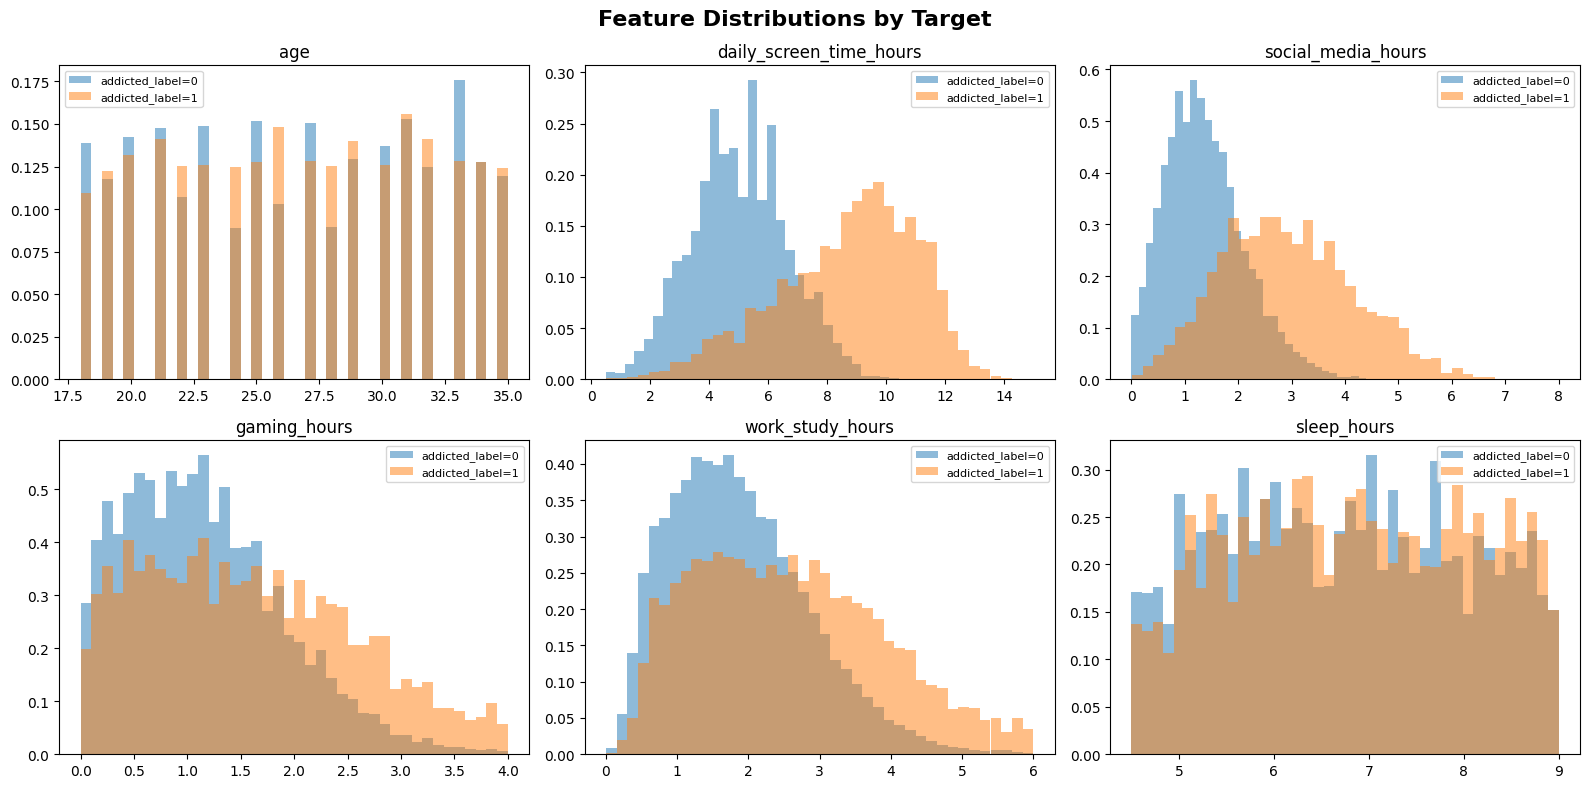

In [4]:
# ==============================================================================
# EDA — Missing Values & Feature Overview
# ==============================================================================
print('Missing values (%) — Train vs Test:')
miss = pd.DataFrame({
    'Train %': train.drop(columns=['id', TARGET]).isnull().mean() * 100,
    'Test %':  test.drop(columns=['id']).isnull().mean() * 100
}).round(2)
print(miss)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
fig.suptitle('Feature Distributions by Target', fontsize=16, fontweight='bold')
num_feats = [c for c in train.columns if c not in ['id', TARGET] 
             and train[c].dtype in ['float64', 'int64']]
for i, col in enumerate(num_feats[:6]):
    ax = axes[i // 3][i % 3]
    for label in [0, 1]:
        subset = train[train[TARGET] == label][col].dropna()
        ax.hist(subset, bins=40, alpha=0.5, label=f'{TARGET}={label}', density=True)
    ax.set_title(col)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [5]:
# ==============================================================================
# FEATURE ENGINEERING & THE STRING TRICK
# ==============================================================================
# The synthetic data has discrete grid patterns.
# Converting continuous features to strings then target-encoding
# reverse-engineers the generator's lookup-table logic.
# ==============================================================================

# Identify feature types
cat_cols = train.select_dtypes(include=['object', 'category']).columns.tolist()
cat_cols = [c for c in cat_cols if c not in ['id']]
num_cols = [c for c in train.columns if c not in ['id', TARGET] + cat_cols]

print(f'Categorical cols: {cat_cols}')
print(f'Numerical cols:   {num_cols}')

# --- STRING TRICK: convert numeric features to string categories ---
# This is the key insight from top competitors. We create string versions
# of numeric features and then target-encode them. Tree models can then
# treat each unique discrete value as a separate bucket.

def apply_string_trick(df, num_cols):
    df = df.copy()
    for col in num_cols:
        df[f'{col}_str'] = df[col].astype(str)
    return df

train = apply_string_trick(train, num_cols)
test  = apply_string_trick(test, num_cols)

str_cols = [f'{c}_str' for c in num_cols]
print(f'\nString-trick columns added: {str_cols}')

# --- TARGET ENCODING for string-trick columns ---
# Uses 5-fold OOF target encoding to prevent leakage
def target_encode_oof(train_df, test_df, cols, target, n_folds=5, seed=42):
    train_df = train_df.copy()
    test_df = test_df.copy()
    global_mean = train_df[target].mean()
    
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    
    for col in cols:
        te_col = f'{col}_te'
        train_df[te_col] = global_mean
        
        for tr_idx, val_idx in skf.split(train_df, train_df[target]):
            means = train_df.iloc[tr_idx].groupby(col)[target].mean()
            train_df.loc[train_df.index[val_idx], te_col] = (
                train_df.iloc[val_idx][col].map(means).fillna(global_mean).values
            )
        
        # For test: use full train encoding
        full_means = train_df.groupby(col)[target].mean()
        test_df[te_col] = test_df[col].map(full_means).fillna(global_mean)
    
    return train_df, test_df

all_str_cat = str_cols + cat_cols
train, test = target_encode_oof(train, test, all_str_cat, TARGET, CFG.N_FOLDS, CFG.SEED)
te_cols = [f'{c}_te' for c in all_str_cat]
print(f'Target-encoded columns: {len(te_cols)}')

# --- LABEL ENCODE original categoricals for tree models ---
for col in cat_cols:
    le_col = LabelEncoder()
    train[col] = train[col].astype(str).fillna('missing')
    test[col]  = test[col].astype(str).fillna('missing')
    le_col.fit(pd.concat([train[col], test[col]]))
    train[col] = le_col.transform(train[col])
    test[col]  = le_col.transform(test[col])

Categorical cols: ['gender', 'stress_level', 'academic_work_impact']
Numerical cols:   ['age', 'daily_screen_time_hours', 'social_media_hours', 'gaming_hours', 'work_study_hours', 'sleep_hours', 'notifications_per_day', 'app_opens_per_day', 'weekend_screen_time']

String-trick columns added: ['age_str', 'daily_screen_time_hours_str', 'social_media_hours_str', 'gaming_hours_str', 'work_study_hours_str', 'sleep_hours_str', 'notifications_per_day_str', 'app_opens_per_day_str', 'weekend_screen_time_str']
Target-encoded columns: 12


In [6]:
# ==============================================================================
# FEATURE SELECTION
# ==============================================================================
# Use raw numeric + label-encoded categoricals + target-encoded features
# Drop the intermediate string columns (they were only for encoding)

FEATURES = num_cols + cat_cols + te_cols
print(f'Total features for modeling: {len(FEATURES)}')

X = train[FEATURES].copy()
y = train[TARGET].values
X_test = test[FEATURES].copy()

# Replace inf with NaN (tree models handle NaN natively)
X = X.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

print(f'X shape: {X.shape} | X_test shape: {X_test.shape}')

Total features for modeling: 24
X shape: (691369, 24) | X_test shape: (296302, 24)


In [7]:
# ==============================================================================
# CROSS-VALIDATION TRAINING ENGINE
# ==============================================================================
def train_model_cv(model_type, X_tr, y_tr, X_te, n_splits, seed):
    oof = np.zeros(len(X_tr))
    test_preds = np.zeros(len(X_te))
    scores = []
    
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    print(f'\n--- Training {model_type} ({n_splits}-fold CV) ---')
    
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_tr, y_tr)):
        Xf_tr, Xf_val = X_tr.iloc[tr_idx], X_tr.iloc[val_idx]
        yf_tr, yf_val = y_tr[tr_idx], y_tr[val_idx]
        
        if model_type == 'LightGBM':
            model = lgb.LGBMClassifier(
                n_estimators=5000, learning_rate=0.02, num_leaves=63,
                max_depth=-1, min_child_samples=20,
                subsample=0.8, colsample_bytree=0.8,
                reg_alpha=0.1, reg_lambda=1.0,
                random_state=seed, verbosity=-1, n_jobs=-1
            )
            model.fit(Xf_tr, yf_tr, eval_set=[(Xf_val, yf_val)],
                      callbacks=[lgb.early_stopping(CFG.EARLY_STOPPING, verbose=False)])
            oof[val_idx] = model.predict_proba(Xf_val)[:, 1]
            test_preds += model.predict_proba(X_te)[:, 1] / n_splits
            
        elif model_type == 'XGBoost':
            model = xgb.XGBClassifier(
                n_estimators=5000, learning_rate=0.02, max_depth=6,
                subsample=0.8, colsample_bytree=0.8,
                reg_alpha=0.1, reg_lambda=1.0,
                tree_method='hist',
                device='cuda' if CFG.USE_GPU else 'cpu',
                random_state=seed, n_jobs=-1,
                early_stopping_rounds=CFG.EARLY_STOPPING, eval_metric='auc'
            )
            model.fit(Xf_tr, yf_tr, eval_set=[(Xf_val, yf_val)], verbose=False)
            oof[val_idx] = model.predict_proba(Xf_val)[:, 1]
            test_preds += model.predict_proba(X_te)[:, 1] / n_splits
            
        elif model_type == 'CatBoost':
            model = CatBoostClassifier(
                iterations=5000, learning_rate=0.02, depth=6,
                l2_leaf_reg=3.0, random_seed=seed,
                task_type='GPU' if CFG.USE_GPU else 'CPU',
                verbose=0, early_stopping_rounds=CFG.EARLY_STOPPING,
                eval_metric='AUC'
            )
            model.fit(Xf_tr, yf_tr, eval_set=(Xf_val, yf_val))
            oof[val_idx] = model.predict_proba(Xf_val)[:, 1]
            test_preds += model.predict_proba(X_te)[:, 1] / n_splits
        
        fold_auc = roc_auc_score(yf_val, oof[val_idx])
        scores.append(fold_auc)
        print(f'  Fold {fold+1} AUC: {fold_auc:.6f}')
    
    overall_auc = roc_auc_score(y_tr, oof)
    print(f'  Overall OOF AUC: {overall_auc:.6f} (std: {np.std(scores):.6f})')
    return oof, test_preds, overall_auc

In [8]:
lgb_oof, lgb_test, lgb_auc = train_model_cv('LightGBM', X, y, X_test, CFG.N_FOLDS, CFG.SEED)


--- Training LightGBM (5-fold CV) ---
  Fold 1 AUC: 0.966166
  Fold 2 AUC: 0.966900
  Fold 3 AUC: 0.967233
  Fold 4 AUC: 0.967275
  Fold 5 AUC: 0.966419
  Overall OOF AUC: 0.966796 (std: 0.000441)


In [9]:
xgb_oof, xgb_test, xgb_auc = train_model_cv('XGBoost', X, y, X_test, CFG.N_FOLDS, CFG.SEED + 1)


--- Training XGBoost (5-fold CV) ---
  Fold 1 AUC: 0.967014
  Fold 2 AUC: 0.966425
  Fold 3 AUC: 0.967596
  Fold 4 AUC: 0.967873
  Fold 5 AUC: 0.967315
  Overall OOF AUC: 0.967244 (std: 0.000500)


In [10]:
cat_oof, cat_test, cat_auc = train_model_cv('CatBoost', X, y, X_test, CFG.N_FOLDS, CFG.SEED + 2)


--- Training CatBoost (5-fold CV) ---


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 1 AUC: 0.966098


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 2 AUC: 0.966948


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 3 AUC: 0.966972


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 4 AUC: 0.966225


Default metric period is 5 because AUC is/are not implemented for GPU


  Fold 5 AUC: 0.965951
  Overall OOF AUC: 0.966438 (std: 0.000434)


In [11]:
# ==============================================================================
# META-STACKING ENSEMBLE
# ==============================================================================
# Use OOF predictions from base models as features for a meta-learner.
# This is the approach that top competitors use for maximum generalization.
# A simple Logistic Regression meta-learner prevents overfitting.
# ==============================================================================
print('\n--- Building Meta-Stacking Ensemble ---')

# Stack OOF predictions
meta_train = np.column_stack([lgb_oof, xgb_oof, cat_oof])
meta_test  = np.column_stack([lgb_test, xgb_test, cat_test])

# Add polynomial interaction features between OOF predictions
meta_train_poly = np.column_stack([
    meta_train,
    lgb_oof * xgb_oof,
    lgb_oof * cat_oof,
    xgb_oof * cat_oof,
])
meta_test_poly = np.column_stack([
    meta_test,
    lgb_test * xgb_test,
    lgb_test * cat_test,
    xgb_test * cat_test,
])

# Meta-learner: Logistic Regression (simple, low variance)
meta_oof = np.zeros(len(meta_train_poly))
meta_test_preds = np.zeros(len(meta_test_poly))
meta_scores = []

skf_meta = StratifiedKFold(n_splits=CFG.N_FOLDS, shuffle=True, random_state=CFG.SEED)
for fold, (tr_idx, val_idx) in enumerate(skf_meta.split(meta_train_poly, y)):
    lr = LogisticRegression(C=1.0, max_iter=1000, random_state=CFG.SEED)
    lr.fit(meta_train_poly[tr_idx], y[tr_idx])
    meta_oof[val_idx] = lr.predict_proba(meta_train_poly[val_idx])[:, 1]
    meta_test_preds += lr.predict_proba(meta_test_poly)[:, 1] / CFG.N_FOLDS
    fold_auc = roc_auc_score(y[val_idx], meta_oof[val_idx])
    meta_scores.append(fold_auc)
    print(f'  Meta Fold {fold+1} AUC: {fold_auc:.6f}')

meta_auc = roc_auc_score(y, meta_oof)
print(f'  Meta-Stack OOF AUC: {meta_auc:.6f}')

# Also compute a simple weighted average as a fallback
w_lgb = lgb_auc / (lgb_auc + xgb_auc + cat_auc)
w_xgb = xgb_auc / (lgb_auc + xgb_auc + cat_auc)
w_cat = cat_auc / (lgb_auc + xgb_auc + cat_auc)

avg_oof = w_lgb * lgb_oof + w_xgb * xgb_oof + w_cat * cat_oof
avg_test = w_lgb * lgb_test + w_xgb * xgb_test + w_cat * cat_test
avg_auc = roc_auc_score(y, avg_oof)
print(f'  Weighted Avg OOF AUC: {avg_auc:.6f}')

# Pick the best strategy
if meta_auc >= avg_auc:
    final_test = meta_test_preds
    final_auc = meta_auc
    strategy = 'Meta-Stacking'
else:
    final_test = avg_test
    final_auc = avg_auc
    strategy = 'Weighted Average'

print(f'\n  BEST STRATEGY: {strategy} (AUC: {final_auc:.6f})')


--- Building Meta-Stacking Ensemble ---
  Meta Fold 1 AUC: 0.966745
  Meta Fold 2 AUC: 0.967435
  Meta Fold 3 AUC: 0.967636
  Meta Fold 4 AUC: 0.967807
  Meta Fold 5 AUC: 0.966975
  Meta-Stack OOF AUC: 0.967304
  Weighted Avg OOF AUC: 0.967297

  BEST STRATEGY: Meta-Stacking (AUC: 0.967304)


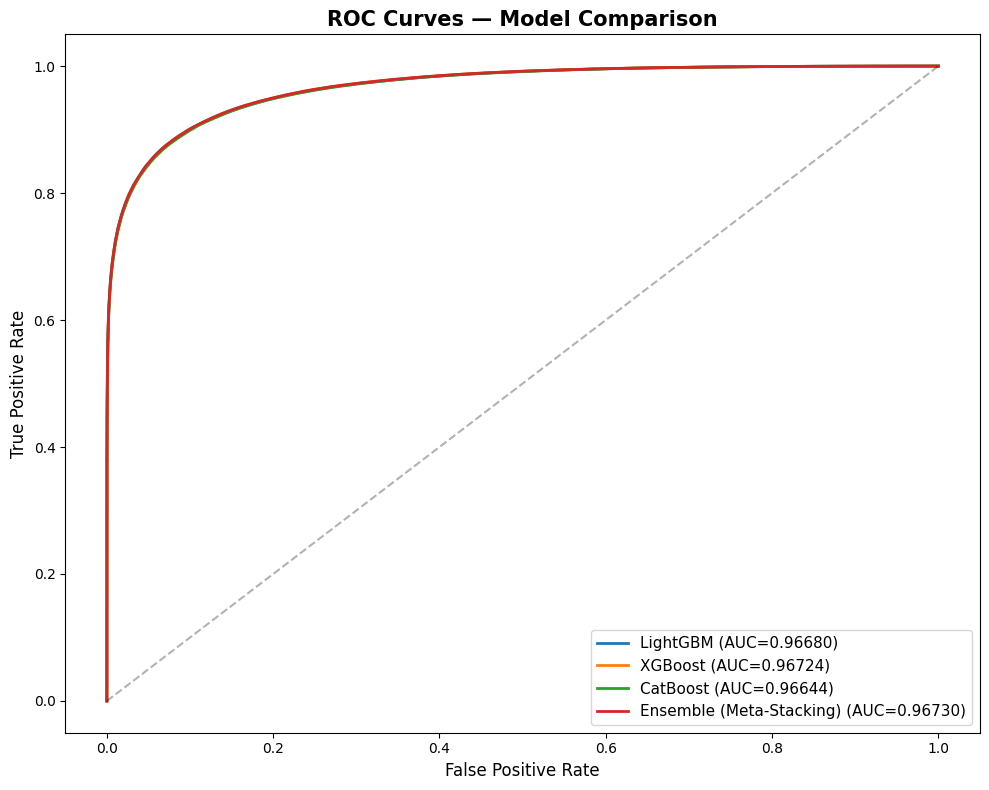


Model Comparison:
        Model  OOF AUC
Meta-Stacking 0.967304
      XGBoost 0.967244
     LightGBM 0.966796
     CatBoost 0.966438


In [12]:
# ==============================================================================
# DIAGNOSTICS — ROC Curves & Model Comparison
# ==============================================================================
fig, ax = plt.subplots(figsize=(10, 8))

for name, oof_preds, auc_score in [
    ('LightGBM', lgb_oof, lgb_auc),
    ('XGBoost', xgb_oof, xgb_auc),
    ('CatBoost', cat_oof, cat_auc),
    (f'Ensemble ({strategy})', meta_oof if strategy == 'Meta-Stacking' else avg_oof, final_auc)
]:
    fpr, tpr, _ = roc_curve(y, oof_preds)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC={auc_score:.5f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3)
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — Model Comparison', fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

# Model comparison table
results = pd.DataFrame({
    'Model': ['LightGBM', 'XGBoost', 'CatBoost', strategy],
    'OOF AUC': [lgb_auc, xgb_auc, cat_auc, final_auc]
}).sort_values('OOF AUC', ascending=False)
print('\nModel Comparison:')
print(results.to_string(index=False))

In [13]:
# ==============================================================================
# SUBMISSION
# ==============================================================================
submission = pd.DataFrame({
    'id': test['id'],
    'addicted_label': final_test
})

print('Submission Preview:')
print(submission.head(10))
print(f'\nShape: {submission.shape}')
print(f'Prediction range: [{submission["addicted_label"].min():.4f}, {submission["addicted_label"].max():.4f}]')
print(f'Mean prediction: {submission["addicted_label"].mean():.4f}')

# Sanity checks
assert len(submission) == len(sample_sub), 'Row count mismatch!'
assert list(submission.columns) == list(sample_sub.columns), 'Column mismatch!'
assert submission['addicted_label'].isnull().sum() == 0, 'Null predictions!'

submission.to_csv('submission.csv', index=False)
print('\nSaved submission.csv')

Submission Preview:
       id  addicted_label
0  691369        0.982685
1  691370        0.973718
2  691371        0.876439
3  691372        0.981666
4  691373        0.982525
5  691374        0.964950
6  691375        0.959876
7  691376        0.280056
8  691377        0.982497
9  691378        0.248556

Shape: (296302, 2)
Prediction range: [0.0564, 0.9827]
Mean prediction: 0.7098

Saved submission.csv


## Key Takeaways

<div style="background:linear-gradient(135deg,#0f172a,#1e1b4b);padding:25px;border-radius:15px;border:1px solid #7B68EE;color:#e2e8f0;">

### What we did:
1. **String Trick** — Converted continuous features to categorical strings, then target-encoded them (OOF-safe). This reverse-engineers the synthetic data generator.
2. **Minimal Feature Engineering** — Relied on raw features + target encodings. Tree models handle the signal well without manual ratios.
3. **3-Model Diversity** — LightGBM + XGBoost + CatBoost each see the data slightly differently.
4. **Meta-Stacking** — Used OOF predictions + polynomial interactions as features for a Logistic Regression meta-learner.
5. **Anti-Overfitting** — 5-Fold StratifiedKFold, early stopping, OOF target encoding, and a simple meta-learner.

### Generalization strategy:
- Native missing value handling (no imputation = less noise)
- OOF target encoding prevents train-set leakage
- Low-variance meta-learner (LogisticRegression) on top of high-variance base models
- Stable fold scores with low standard deviation

</div>